# 03 實驗:模型、不平衡、洩漏、閾值、解釋、公平性、測試集

照 Exercise 2 的計畫依序完成。每一節最後都會把表格存到 `reports/`、圖存到 `reports/figures/`。

| 節 | 內容 | 對應研究問題 |
|---|---|---|
| 0 | 載入資料、交叉驗證設定(重複分層 10 折 × 3) | — |
| 1 | 特徵修正檢查(職涯停滯、log 月薪) | — |
| 2 | Gender 是否放進模型 | 公平性 |
| 3 | 實驗 A + B:5 種模型 × 4 種不平衡處理 | 預測能力 |
| 4 | 實驗 C:正確流程 vs. 洩漏流程 | 方法嚴謹性 |
| 5 | Optuna 調參,決定最終模型 | 預測能力 |
| 6 | 實驗 D:決策閾值與成本 | 決策成本 |
| 7 | Permutation Importance 與 SHAP | 可解釋性 |
| 8 | 公平性(性別、年齡層) | 公平性 |
| 9 | 測試集最終評估(只開這一次) | — |

## 0. 設定

In [1]:
import os, sys, warnings
from pathlib import Path

root = Path.cwd()
while not (root / "src").exists() and root != root.parent:
    root = root.parent
os.chdir(root); sys.path.insert(0, str(root))
os.environ["PYTHONPATH"] = str(root)          # 平行運算的子行程也找得到 src
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score,
                             precision_score, f1_score, accuracy_score, confusion_matrix,
                             roc_curve, precision_recall_curve)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from src.preprocessing import (RANDOM_STATE, get_train_test, make_preprocessor,
                               FeatureEngineer, age_group, DERIVED_COLS)

X_train, X_test, y_train, y_test = get_train_test()
print("train:", X_train.shape, f"離職 {y_train.sum()} 人;test:", X_test.shape, f"離職 {y_test.sum()} 人")

# 重複分層 10 折 × 3 = 30 次驗證;所有實驗共用同一組切分
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=RANDOM_STATE)
splits = list(cv.split(X_train, y_train))

REPORTS = Path("reports"); FIG = REPORTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# 圖表樣式:中文字型 + 固定配色(第 1 色藍、第 2 色橘…依序使用)
plt.rcParams.update({
    "font.sans-serif": ["Microsoft JhengHei", "Microsoft YaHei", "DejaVu Sans"],
    "axes.unicode_minus": False, "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

train: (1176, 30) 離職 190 人;test: (294, 30) 離職 47 人


In [2]:
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision",
           "recall": "recall", "precision": "precision", "f1": "f1"}
POS_W = (1 - y_train.mean()) / y_train.mean()      # 留任 : 離職 ≈ 5.2 : 1
MODELS = ["LR", "DT", "RF", "XGB", "LGBM"]
IMBS = ["none", "weight", "smote", "under"]
IMB_NAME = {"none": "不處理", "weight": "class weight", "smote": "SMOTE", "under": "下採樣"}
DROP = ()   # 第 2 節決定要不要拿掉 Gender


def make_model(name, imb="none", params=None, drop=None):
    """前處理 + (重抽樣) + 模型,全部包在同一個 Pipeline,只在訓練折內 fit。"""
    w = imb == "weight"
    p = params or {}
    if name == "LR":
        kind, m = "linear", LogisticRegression(max_iter=5000, class_weight="balanced" if w else None)
    elif name == "DT":
        kind, m = "tree", DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced" if w else None)
    elif name == "RF":
        kind, m = "tree", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1,
                                                 class_weight="balanced" if w else None)
    elif name == "XGB":
        kind, m = "tree", XGBClassifier(random_state=RANDOM_STATE, n_jobs=1, verbosity=0,
                                        scale_pos_weight=POS_W if w else 1.0)
    elif name == "LGBM":
        kind, m = "tree", LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1,
                                         scale_pos_weight=POS_W if w else 1.0)
    else:
        raise ValueError(name)
    m.set_params(**p)
    # 前兩步固定是 features、encode(imblearn 的 Pipeline 不能再包一層 Pipeline,所以攤平)
    steps = list(make_preprocessor(kind, drop=DROP if drop is None else drop).steps)
    if imb == "smote":
        steps.append(("resample", SMOTE(random_state=RANDOM_STATE)))
    if imb == "under":
        steps.append(("resample", RandomUnderSampler(random_state=RANDOM_STATE)))
    steps.append(("model", m))
    return Pipeline(steps)


def run_cv(pipe, X=X_train, y=y_train, cv=splits):
    s = cross_validate(pipe, X, y, cv=cv, scoring=SCORING, n_jobs=-1)
    return {k: s["test_" + k] for k in SCORING}


def summarize(res):
    """res: {名稱: run_cv 結果} → 平均 ± 標準差表格。"""
    rows = {}
    for name, s in res.items():
        rows[name] = {"ROC AUC": s["roc_auc"].mean(), "ROC sd": s["roc_auc"].std(),
                      "PR AUC": s["pr_auc"].mean(), "PR sd": s["pr_auc"].std(),
                      "Recall": s["recall"].mean(), "Precision": s["precision"].mean(),
                      "F1": s["f1"].mean()}
    return pd.DataFrame(rows).T.round(3)


def oof_proba(pipe, X=X_train, y=y_train):
    """折外預測機率:3 輪 10 折各給每人一個『沒看過他的模型』的預測,再取 3 輪平均。"""
    from joblib import Parallel, delayed
    def fit_pred(tr, va):
        m = clone(pipe).fit(X.iloc[tr], y.iloc[tr])
        return va, m.predict_proba(X.iloc[va])[:, 1]
    out = Parallel(n_jobs=-1)(delayed(fit_pred)(tr, va) for tr, va in splits)
    p = np.zeros(len(y)); n = np.zeros(len(y))
    for va, pr in out:
        p[va] += pr; n[va] += 1
    return p / n

## 1. 特徵修正檢查

Exercise 2 發現「職涯停滯」方向和預期相反(離職者中位數反而較低),原因是離職者多半年資很短。
現在改成**只對年資 ≥ 2 年的人計算**,其餘設為 0;另外 MonthlyIncome 改成取 log。

In [3]:
F = FeatureEngineer().fit(X_train).transform(X_train)
senior = X_train["YearsAtCompany"] >= 2
check = pd.DataFrame({
    "年資<2 年 離職率": [y_train[~senior].mean()],
    "年資≥2 年 離職率": [y_train[senior].mean()],
    "停滯(年資≥2) 留任者平均": [F.loc[senior & (y_train == 0), "stagnation"].mean()],
    "停滯(年資≥2) 離職者平均": [F.loc[senior & (y_train == 1), "stagnation"].mean()],
}).round(3)
check

,年資<2 年 離職率,年資≥2 年 離職率,停滯(年資≥2) 留任者平均,停滯(年資≥2) 離職者平均
0,0.386,0.125,0.314,0.408


## 2. Gender 是否放進模型

比較含 / 不含 Gender 的交叉驗證分數。若拿掉後分數幾乎不變(差距 < 0.01),
就**不讓模型直接使用性別**,Gender 只留給第 8 節的公平性分析。

In [4]:
res_gender = {}
for name in ["LR", "LGBM"]:
    res_gender[f"{name} 含 Gender"] = run_cv(make_model(name, "weight", drop=()))
    res_gender[f"{name} 不含 Gender"] = run_cv(make_model(name, "weight", drop=("Gender",)))
tab_gender = summarize(res_gender)
display(tab_gender)

diff = max(abs(tab_gender.loc[f"{n} 含 Gender", "ROC AUC"] - tab_gender.loc[f"{n} 不含 Gender", "ROC AUC"])
           for n in ["LR", "LGBM"])
DROP = ("Gender",) if diff < 0.01 else ()
print(f"最大 ROC AUC 差距 {diff:.3f} → DROP = {DROP}")
tab_gender.to_csv(REPORTS / "exp_gender.csv")

,ROC AUC,ROC sd,PR AUC,PR sd,Recall,Precision,F1
LR 含 Gender,0.837,0.055,0.650,0.090,0.751,0.390,0.511
LR 不含 Gender,0.837,0.056,0.649,0.093,0.761,0.395,0.519
LGBM 含 Gender,0.803,0.055,0.572,0.096,0.416,0.639,0.491
LGBM 不含 Gender,0.801,0.054,0.562,0.103,0.414,0.616,0.482


最大 ROC AUC 差距 0.002 → DROP = ('Gender',)


## 3. 實驗 A + B:模型 × 不平衡處理

5 種模型(預設參數)× 4 種不平衡處理,共 20 組,外加「全部預測留任」的 naive 基準。
Recall / Precision / F1 都是用預設閾值 0.5 算的;閾值的影響留到實驗 D。

In [5]:
res_ab = {"naive(全部留任)": run_cv(Pipeline(list(make_preprocessor("linear", drop=DROP).steps)
                                           + [("model", DummyClassifier(strategy="prior"))]))}
for name in MODELS:
    for imb in IMBS:
        res_ab[f"{name} | {IMB_NAME[imb]}"] = run_cv(make_model(name, imb))
    print(name, "done")

tab_ab = summarize(res_ab)
tab_ab.to_csv(REPORTS / "exp_AB.csv")
tab_ab.sort_values("PR AUC", ascending=False)

LR done


DT done


RF done


XGB done


LGBM done


,ROC AUC,ROC sd,PR AUC,PR sd,Recall,Precision,F1
LR | 不處理,0.845,0.053,0.681,0.089,0.472,0.797,0.586
LR | class weight,0.837,0.056,0.649,0.093,0.761,0.395,0.519
LR | SMOTE,0.834,0.054,0.642,0.093,0.744,0.408,0.525
LR | 下採樣,0.824,0.056,0.605,0.115,0.770,0.365,0.493
LGBM | 不處理,0.802,0.055,0.568,0.100,0.318,0.705,0.427
LGBM | class weight,0.801,0.054,0.562,0.103,0.414,0.616,0.482
RF | class weight,0.794,0.058,0.561,0.105,0.386,0.641,0.476
LGBM | SMOTE,0.792,0.059,0.558,0.098,0.368,0.663,0.465
RF | 不處理,0.803,0.051,0.558,0.096,0.212,0.807,0.328
XGB | 不處理,0.784,0.059,0.558,0.102,0.330,0.695,0.435


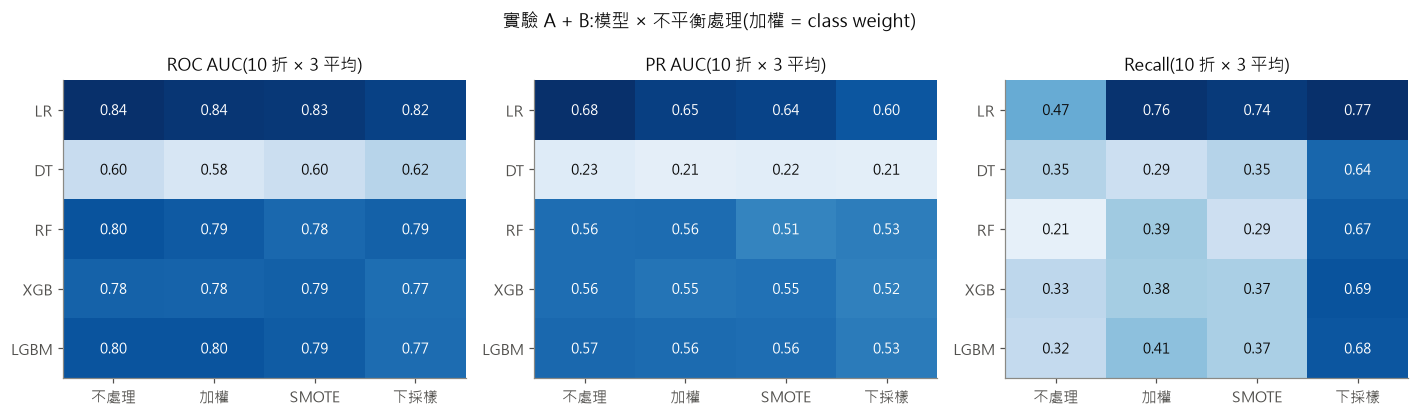

In [6]:
def grid(metric):
    g = pd.DataFrame({IMB_NAME[i]: [tab_ab.loc[f"{m} | {IMB_NAME[i]}", metric] for m in MODELS]
                      for i in IMBS}, index=MODELS)
    return g

SHORT = {"不處理": "不處理", "class weight": "加權", "SMOTE": "SMOTE", "下採樣": "下採樣"}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, metric in zip(axes, ["ROC AUC", "PR AUC", "Recall"]):
    g = grid(metric)
    im = ax.imshow(g.values, cmap="Blues", aspect="auto",
                   vmin=g.values.min() - 0.05, vmax=g.values.max())
    ax.set_xticks(range(len(g.columns)), [SHORT[c] for c in g.columns])
    ax.set_yticks(range(len(g.index)), g.index)
    ax.grid(False)
    for i in range(g.shape[0]):
        for j in range(g.shape[1]):
            v = g.values[i, j]
            dark = v > (g.values.min() + g.values.max()) / 2
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if dark else "#0b0b0b")
    ax.set_title(f"{metric}(10 折 × 3 平均)", fontsize=11)
fig.suptitle("實驗 A + B:模型 × 不平衡處理(加權 = class weight)", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "exp_ab_heatmap.png", bbox_inches="tight")
plt.show()

## 4. 實驗 C:資料洩漏讓分數虛高多少

| 流程 | 做法 |
|---|---|
| 正確 | 前處理(含同職級平均月薪、標準化、One-hot)和 SMOTE 都包在 Pipeline,只在訓練折 fit |
| 洩漏 1:前處理先 fit | 先用**整個訓練集**算好前處理,再做交叉驗證 |
| 洩漏 2:SMOTE 在切分前 | 先對整個訓練集做 SMOTE,再切折;合成樣本的「鄰居」會同時出現在訓練折與驗證折 |

In [7]:
def leaky_prep_cv(name):
    """洩漏 1:前處理用整個訓練集 fit,之後只對模型做交叉驗證。"""
    pipe = make_model(name, "none")
    Xt = pipe[:2].fit_transform(X_train, y_train)
    return run_cv(Pipeline([("model", pipe.named_steps["model"])]), X=Xt)


def leaky_smote_cv(name):
    """洩漏 2:先 SMOTE 整個訓練集,再對擴增後的資料切 10 折 × 3。"""
    pipe = make_model(name, "none")
    Xt = pipe[:2].fit_transform(X_train, y_train)
    Xs, ys = SMOTE(random_state=RANDOM_STATE).fit_resample(Xt, y_train)
    cv_s = list(RepeatedStratifiedKFold(n_splits=10, n_repeats=3,
                                        random_state=RANDOM_STATE).split(Xs, ys))
    return run_cv(Pipeline([("model", pipe.named_steps["model"])]), X=Xs, y=ys, cv=cv_s)


rows = []
for name in ["LR", "RF"]:
    pairs = [("前處理", res_ab[f"{name} | 不處理"], leaky_prep_cv(name)),
             ("SMOTE", res_ab[f"{name} | SMOTE"], leaky_smote_cv(name))]
    for what, ok, leak in pairs:
        for metric, key in [("ROC AUC", "roc_auc"), ("PR AUC", "pr_auc")]:
            rows.append({"模型": name, "洩漏來源": what, "指標": metric,
                         "正確流程": ok[key].mean(), "洩漏流程": leak[key].mean(),
                         "虛高": leak[key].mean() - ok[key].mean()})
tab_c = pd.DataFrame(rows).round(3)
tab_c.to_csv(REPORTS / "exp_C_leakage.csv", index=False)
tab_c

,模型,洩漏來源,指標,正確流程,洩漏流程,虛高
0,LR,前處理,ROC AUC,0.845,0.845,0.000
1,LR,前處理,PR AUC,0.681,0.682,0.000
2,LR,SMOTE,ROC AUC,0.834,0.891,0.057
3,LR,SMOTE,PR AUC,0.642,0.899,0.257
4,RF,前處理,ROC AUC,0.803,0.804,0.001
5,RF,前處理,PR AUC,0.558,0.563,0.005
6,RF,SMOTE,ROC AUC,0.777,0.976,0.199
7,RF,SMOTE,PR AUC,0.513,0.980,0.468


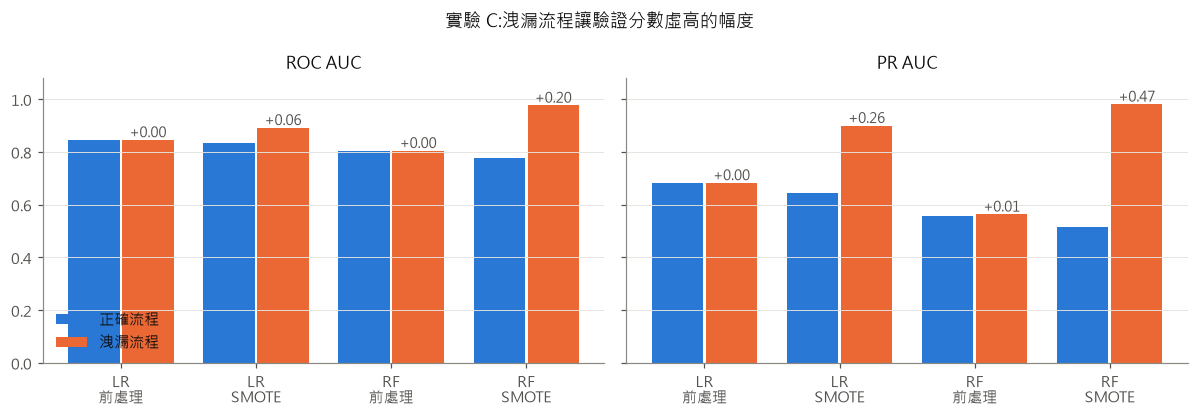

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, metric in zip(axes, ["ROC AUC", "PR AUC"]):
    t = tab_c[tab_c["指標"] == metric].reset_index(drop=True)
    labels = [f"{r.模型}\n{r.洩漏來源}" for r in t.itertuples()]
    x = np.arange(len(t)); w = 0.38
    ax.bar(x - w / 2 - 0.01, t["正確流程"], w, color=C[0], label="正確流程")
    ax.bar(x + w / 2 + 0.01, t["洩漏流程"], w, color=C[1], label="洩漏流程")
    for i, r in t.iterrows():
        ax.text(i + w / 2 + 0.01, r["洩漏流程"] + 0.01, f"+{r['虛高']:.2f}", ha="center",
                fontsize=9, color="#52514e")
    ax.set_xticks(x, labels); ax.set_ylim(0, 1.08); ax.set_title(metric, fontsize=11)
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, loc="lower left")
fig.suptitle("實驗 C:洩漏流程讓驗證分數虛高的幅度", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "exp_c_leakage.png", bbox_inches="tight")
plt.show()

## 5. Optuna 調參,決定最終模型

取實驗 A + B 中 PR AUC 最高的兩組(模型 + 不平衡處理),各跑 40 次 Optuna 試驗。
- 調參時用**另一組**切分(5 折 × 2,種子 0)計分,避免對主要的 30 折切分過度調整。
- 調好的參數再回到主要的 10 折 × 3 評估,和未調參版本公平比較。

In [9]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

tune_cv = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=0).split(X_train, y_train))

def space(trial, name):
    if name == "LR":
        return {"C": trial.suggest_float("C", 1e-3, 10, log=True)}
    if name == "DT":
        return {"max_depth": trial.suggest_int("max_depth", 2, 10),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 50)}
    if name == "RF":
        return {"n_estimators": trial.suggest_int("n_estimators", 100, 600, step=50),
                "max_depth": trial.suggest_int("max_depth", 3, 20),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
                "max_features": trial.suggest_categorical("max_features", ["sqrt", 0.3, 0.5])}
    if name == "XGB":
        return {"n_estimators": trial.suggest_int("n_estimators", 100, 600, step=50),
                "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
                "max_depth": trial.suggest_int("max_depth", 2, 6),
                "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
                "subsample": trial.suggest_float("subsample", 0.6, 1.0),
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
                "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True)}
    if name == "LGBM":
        return {"n_estimators": trial.suggest_int("n_estimators", 100, 600, step=50),
                "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
                "num_leaves": trial.suggest_int("num_leaves", 4, 31),
                "min_child_samples": trial.suggest_int("min_child_samples", 5, 60),
                "subsample": trial.suggest_float("subsample", 0.6, 1.0), "subsample_freq": 1,
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
                "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True)}


def tune(name, imb, n_trials=40):
    def objective(trial):
        s = cross_validate(make_model(name, imb, space(trial, name)), X_train, y_train,
                           cv=tune_cv, scoring="average_precision", n_jobs=-1)
        return s["test_score"].mean()
    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=n_trials)
    return study


ranked = tab_ab.drop(index="naive(全部留任)").sort_values("PR AUC", ascending=False)
top2 = []
for label in ranked.index:                       # 前兩名,且是不同模型
    name, imb_label = [s.strip() for s in label.split("|")]
    if name not in [t[0] for t in top2]:
        top2.append((name, {v: k for k, v in IMB_NAME.items()}[imb_label]))
    if len(top2) == 2:
        break
print("要調參的兩組:", top2)

tuned = {}
for name, imb in top2:
    study = tune(name, imb)
    params = {**study.best_params, **({"subsample_freq": 1} if name == "LGBM" else {})}
    tuned[(name, imb)] = params
    print(f"{name} | {IMB_NAME[imb]}  調參 PR AUC {study.best_value:.3f}  參數 {params}")

要調參的兩組: [('LR', 'none'), ('LGBM', 'none')]


LR | 不處理  調參 PR AUC 0.675  參數 {'C': 0.12915629316911423}


LGBM | 不處理  調參 PR AUC 0.634  參數 {'n_estimators': 500, 'learning_rate': 0.022077857350248736, 'num_leaves': 4, 'min_child_samples': 33, 'subsample': 0.6598727479756666, 'colsample_bytree': 0.5128457911507142, 'reg_lambda': 0.06678724239172527, 'subsample_freq': 1}


In [10]:
res_tune = {}
for (name, imb), params in tuned.items():
    res_tune[f"{name} | {IMB_NAME[imb]}(預設)"] = res_ab[f"{name} | {IMB_NAME[imb]}"]
    res_tune[f"{name} | {IMB_NAME[imb]}(調參後)"] = run_cv(make_model(name, imb, params))
tab_tune = summarize(res_tune)
tab_tune.to_csv(REPORTS / "exp_tuning.csv")
display(tab_tune)

# 最終模型:PR AUC 最高的那一組(調參沒贏就用預設參數)
best = tab_tune["PR AUC"].idxmax()
FINAL_NAME, imb_label = [s.strip() for s in best.split("|")]
FINAL_IMB = {v: k for k, v in IMB_NAME.items()}[imb_label.split("(")[0]]
FINAL_PARAMS = tuned[(FINAL_NAME, FINAL_IMB)] if "調參後" in best else {}
final_pipe = make_model(FINAL_NAME, FINAL_IMB, FINAL_PARAMS)
print("最終模型:", best, FINAL_PARAMS)

,ROC AUC,ROC sd,PR AUC,PR sd,Recall,Precision,F1
LR | 不處理(預設),0.845,0.053,0.681,0.089,0.472,0.797,0.586
LR | 不處理(調參後),0.842,0.056,0.676,0.099,0.409,0.832,0.542
LGBM | 不處理(預設),0.802,0.055,0.568,0.100,0.318,0.705,0.427
LGBM | 不處理(調參後),0.826,0.053,0.641,0.111,0.349,0.797,0.477


最終模型: LR | 不處理(預設) {}


## 6. 實驗 D:決策閾值與成本

用最終模型的**折外預測機率**(訓練集,沒碰測試集)比較不同閾值。
成本假設:FP(誤判會離職,多做一次留才面談)= 1,FN(漏掉真的會離職的人)= 3 或 5。
每位員工的平均成本 = (FN 人數 × FN 成本 + FP 人數 × 1) / 總人數,越低越好。

In [11]:
oof = oof_proba(final_pipe)
print(f"折外 ROC AUC {roc_auc_score(y_train, oof):.3f}  PR AUC {average_precision_score(y_train, oof):.3f}")

def at_threshold(y, p, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"閾值": round(t, 2), "Recall": tp / (tp + fn), "Precision": tp / max(tp + fp, 1),
            "F1": f1_score(y, pred), "判定離職人數": int(pred.sum()), "FP": int(fp), "FN": int(fn),
            "成本(FN=3)": (3 * fn + fp) / len(y), "成本(FN=5)": (5 * fn + fp) / len(y)}

grid_t = np.round(np.arange(0.05, 0.951, 0.01), 2)
curve = pd.DataFrame([at_threshold(y_train, oof, t) for t in grid_t])
BEST_T = {c: float(curve.loc[curve[f"成本(FN={c})"].idxmin(), "閾值"]) for c in (3, 5)}
MAIN_C = 5
THRESHOLD = BEST_T[MAIN_C]

tab_d = pd.DataFrame([at_threshold(y_train, oof, t) for t in [0.5, 0.4, 0.3, BEST_T[3], BEST_T[5]]])
tab_d.insert(0, "情境", ["預設 0.5", "0.4", "0.3", "最低成本(FN=3)", "最低成本(FN=5)"])
tab_d = tab_d.round(3)
tab_d.to_csv(REPORTS / "exp_D_threshold.csv", index=False)
print("最低成本閾值:", BEST_T, " 主要情境 FN=5 → 閾值", THRESHOLD)
tab_d

折外 ROC AUC 0.844  PR AUC 0.673


最低成本閾值: {3: 0.29, 5: 0.22}  主要情境 FN=5 → 閾值 0.22


,情境,閾值,Recall,Precision,F1,判定離職人數,FP,FN,成本(FN=3),成本(FN=5)
0,預設 0.5,0.50,0.468,0.802,0.591,111,22,101,0.276,0.448
1,0.4,0.40,0.553,0.669,0.605,157,52,85,0.261,0.406
2,0.3,0.30,0.647,0.564,0.603,218,95,67,0.252,0.366
3,最低成本(FN=3),0.29,0.663,0.560,0.607,225,99,64,0.247,0.356
4,最低成本(FN=5),0.22,0.721,0.472,0.571,290,153,53,0.265,0.355


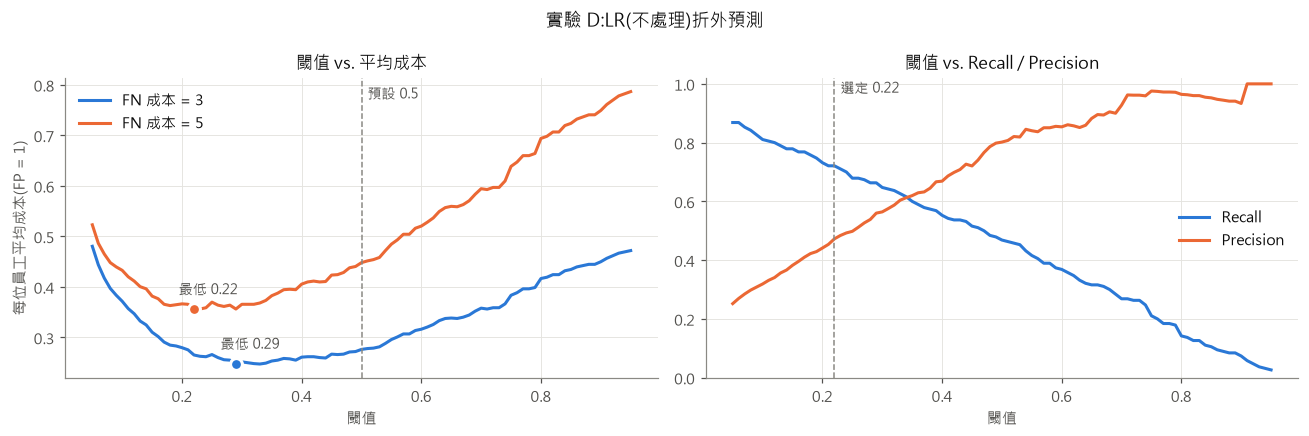

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
for c, col in [(3, C[0]), (5, C[1])]:
    ax.plot(curve["閾值"], curve[f"成本(FN={c})"], color=col, lw=2, label=f"FN 成本 = {c}")
    t = BEST_T[c]; v = curve.loc[curve["閾值"] == t, f"成本(FN={c})"].item()
    ax.scatter([t], [v], s=60, color=col, edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(f"最低 {t:.2f}", (t, v), xytext=(-10, 10), textcoords="offset points",
                fontsize=9, color="#52514e")
ax.axvline(0.5, color="#8a8984", lw=1, ls="--")
ax.text(0.51, ax.get_ylim()[1] * 0.95, "預設 0.5", fontsize=9, color="#52514e")
ax.set_xlabel("閾值"); ax.set_ylabel("每位員工平均成本(FP = 1)")
ax.set_title("閾值 vs. 平均成本", fontsize=11); ax.legend(frameon=False)

ax = axes[1]
ax.plot(curve["閾值"], curve["Recall"], color=C[0], lw=2, label="Recall")
ax.plot(curve["閾值"], curve["Precision"], color=C[1], lw=2, label="Precision")
ax.axvline(THRESHOLD, color="#8a8984", lw=1, ls="--")
ax.text(THRESHOLD + 0.01, 0.97, f"選定 {THRESHOLD:.2f}", fontsize=9, color="#52514e")
ax.set_xlabel("閾值"); ax.set_ylim(0, 1.02)
ax.set_title("閾值 vs. Recall / Precision", fontsize=11); ax.legend(frameon=False, loc="center right")
fig.suptitle(f"實驗 D:{FINAL_NAME}({IMB_NAME[FINAL_IMB]})折外預測", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "exp_d_threshold.png", bbox_inches="tight")
plt.show()

## 7. 可解釋性

- **Permutation Importance**:在第一輪 10 折的每個驗證折上,把一個**原始欄位**打亂,看 PR AUC 掉多少(掉越多越重要)。
  打亂月薪也會連帶影響由它算出的薪資壓力,所以這是「原始欄位層級」的重要性。
- **SHAP**:用整個訓練集 fit 最終模型,看每個特徵把預測往「離職」或「留任」推多少。

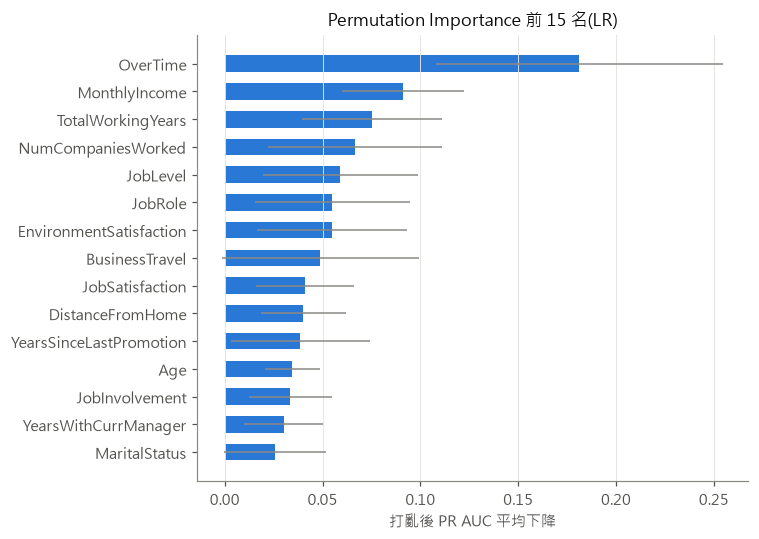

,importance,sd
OverTime,0.1813,0.0734
MonthlyIncome,0.0910,0.0313
TotalWorkingYears,0.0752,0.0356
NumCompaniesWorked,0.0666,0.0444
JobLevel,0.0590,0.0396
JobRole,0.0550,0.0396
EnvironmentSatisfaction,0.0546,0.0383
BusinessTravel,0.0489,0.0502
JobSatisfaction,0.0410,0.0251
DistanceFromHome,0.0402,0.0219


In [13]:
from sklearn.inspection import permutation_importance
from joblib import Parallel, delayed

def pi_fold(tr, va):
    m = clone(final_pipe).fit(X_train.iloc[tr], y_train.iloc[tr])
    r = permutation_importance(m, X_train.iloc[va], y_train.iloc[va], scoring="average_precision",
                               n_repeats=10, random_state=RANDOM_STATE)
    return r.importances_mean

pis = Parallel(n_jobs=-1)(delayed(pi_fold)(tr, va) for tr, va in splits[:10])
pi = pd.DataFrame(pis, columns=X_train.columns)
tab_pi = pd.DataFrame({"importance": pi.mean(), "sd": pi.std()}).sort_values("importance", ascending=False)
tab_pi.round(4).to_csv(REPORTS / "permutation_importance.csv")

top = tab_pi.head(15)[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top["importance"], xerr=top["sd"], color=C[0], height=0.6,
        error_kw={"ecolor": "#8a8984", "lw": 1})
ax.set_xlabel("打亂後 PR AUC 平均下降")
ax.set_title(f"Permutation Importance 前 15 名({FINAL_NAME})", fontsize=11)
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG / "permutation_importance.png", bbox_inches="tight")
plt.show()
tab_pi.head(10).round(4)

Background dataset has 1176 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1176 when initializing the masker.


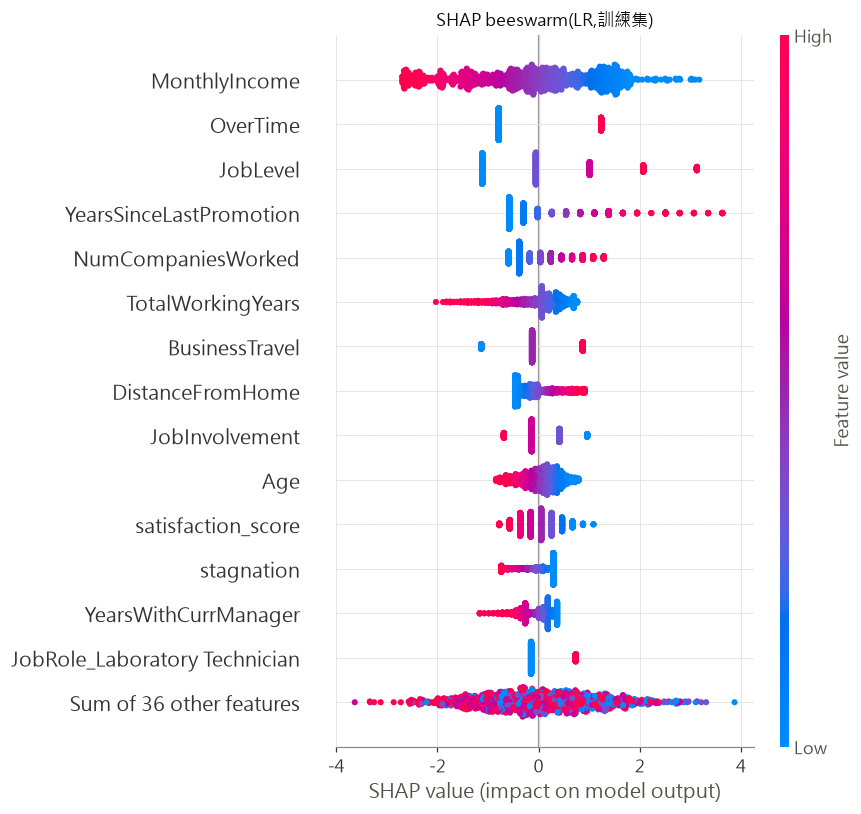

MonthlyIncome              1.0620
OverTime                   0.9171
JobLevel                   0.8623
YearsSinceLastPromotion    0.6433
NumCompaniesWorked         0.4350
TotalWorkingYears          0.4134
BusinessTravel             0.3766
DistanceFromHome           0.3443
JobInvolvement             0.3029
Age                        0.2984
dtype: float64

In [14]:
import shap

fitted = clone(final_pipe).fit(X_train, y_train)
Xt = fitted[:2].transform(X_train)          # 只做前處理(features + encode)
model = fitted.named_steps["model"]

if FINAL_NAME == "LR":
    explainer = shap.LinearExplainer(model, Xt)
else:
    explainer = shap.TreeExplainer(model)
sv = explainer(Xt)
if sv.values.ndim == 3:            # RF / DT 會輸出兩個類別,只取「離職」
    sv = sv[:, :, 1]

plt.figure()
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title(f"SHAP beeswarm({FINAL_NAME},訓練集)", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "shap_beeswarm.png", bbox_inches="tight")
plt.show()

shap_rank = pd.Series(np.abs(sv.values).mean(axis=0), index=Xt.columns).sort_values(ascending=False)
shap_rank.round(4).to_csv(REPORTS / "shap_mean_abs.csv", header=["mean_abs_shap"])
shap_rank.head(10).round(4)

員工 row 463:折外預測機率 0.99,實際離職


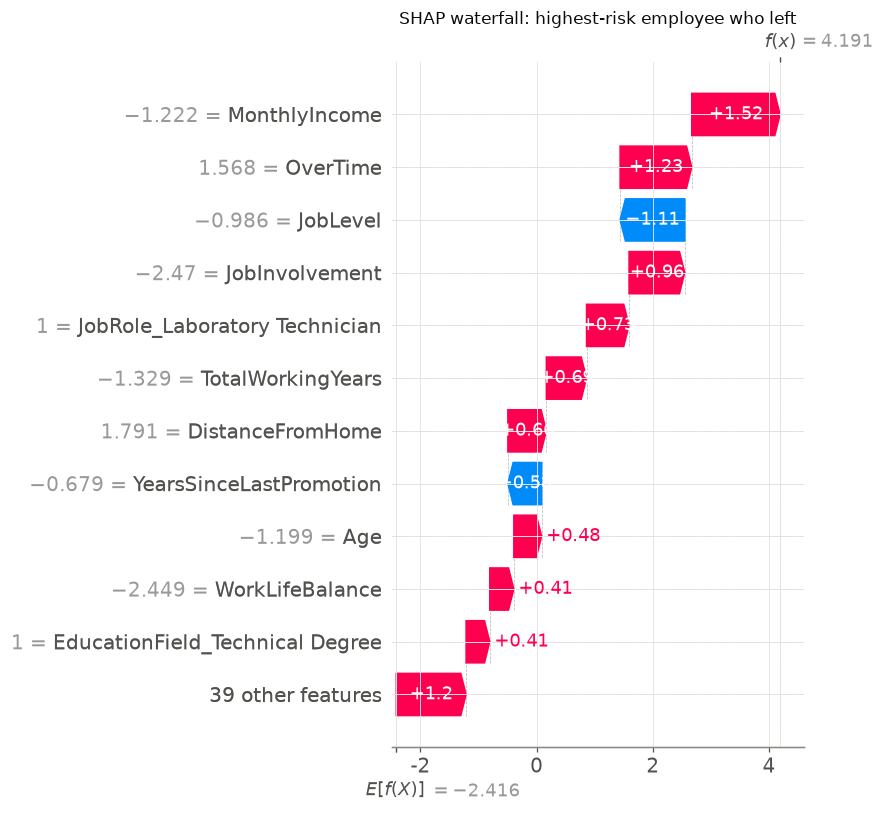

Age                                    26
JobRole             Laboratory Technician
OverTime                              Yes
MonthlyIncome                        2340
YearsAtCompany                          1
StockOptionLevel                        0
MaritalStatus                      Single
JobSatisfaction                         4
Name: 463, dtype: object

In [15]:
# 單一員工:訓練集中折外預測離職機率最高、而且真的離職的人
i = int(np.argmax(np.where(y_train.values == 1, oof, -1)))
print(f"員工 row {X_train.index[i]}:折外預測機率 {oof[i]:.2f},實際離職")
# SHAP 的負號是 U+2212,正黑體沒有這個字,所以這張圖改用 DejaVu Sans、標題用英文
# 圖中欄位左邊的數字是「標準化後」的值(例如 MonthlyIncome = −1.2 代表比平均低 1.2 個標準差)
with plt.rc_context({"font.sans-serif": ["DejaVu Sans"]}):
    plt.figure()
    shap.plots.waterfall(sv[i], max_display=12, show=False)
    plt.title("SHAP waterfall: highest-risk employee who left", fontsize=11)
    plt.tight_layout(); plt.savefig(FIG / "shap_waterfall.png", bbox_inches="tight")
    plt.show()
X_train.iloc[i][["Age", "JobRole", "OverTime", "MonthlyIncome", "YearsAtCompany",
                 "StockOptionLevel", "MaritalStatus", "JobSatisfaction"]]

## 8. 公平性

用第 6 節的折外預測與選定閾值,依性別與年齡層比較:
- **預測離職率**:被模型標記為高風險的比例
- **FPR**:實際留任、卻被標記為會離職的比例(被多關心 / 被貼標籤)
- **FNR**:實際離職、卻沒被抓到的比例(錯過留才機會)

Gender 沒有放進模型(若第 2 節決定拿掉),這裡檢查「沒用性別」是否就代表結果對各性別一致。

In [16]:
pred = (oof >= THRESHOLD).astype(int)
groups = {"性別": X_train["Gender"], "年齡層": age_group(X_train["Age"]).astype(str)}

rows = []
for gname, g in groups.items():
    for level in sorted(g.unique()):
        m = (g == level).values
        yt, yp = y_train.values[m], pred[m]
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        rows.append({"分組": gname, "群組": level, "人數": int(m.sum()), "實際離職人數": int(yt.sum()),
                     "實際離職率": yt.mean(), "預測離職率": yp.mean(),
                     "FPR": fp / (fp + tn), "FNR": fn / (fn + tp),
                     "ROC AUC": roc_auc_score(yt, oof[m])})
tab_fair = pd.DataFrame(rows).round(3)
tab_fair.to_csv(REPORTS / "fairness.csv", index=False)
tab_fair

,分組,群組,人數,實際離職人數,實際離職率,預測離職率,FPR,FNR,ROC AUC
0,性別,Female,472,71,0.150,0.252,0.162,0.239,0.856
1,性別,Male,704,119,0.169,0.243,0.150,0.303,0.840
2,年齡層,30-39,497,75,0.151,0.227,0.145,0.307,0.835
3,年齡層,40+,421,41,0.097,0.159,0.118,0.463,0.745
4,年齡層,<30,258,74,0.287,0.426,0.255,0.149,0.887


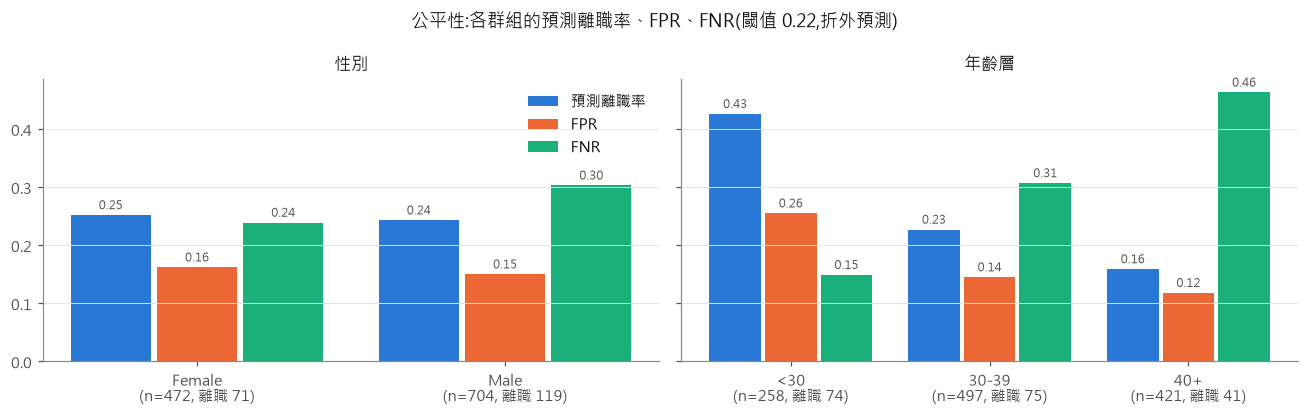

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, gname in zip(axes, ["性別", "年齡層"]):
    t = tab_fair[tab_fair["分組"] == gname].reset_index(drop=True)
    if gname == "年齡層":
        t = t.set_index("群組").loc[["<30", "30-39", "40+"]].reset_index()
    x = np.arange(len(t)); w = 0.26
    for k, (col, color) in enumerate([("預測離職率", C[0]), ("FPR", C[1]), ("FNR", C[2])]):
        bars = ax.bar(x + (k - 1) * (w + 0.02), t[col], w, color=color, label=col)
        for b, v in zip(bars, t[col]):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center",
                    fontsize=8, color="#52514e")
    ax.set_xticks(x, [f"{g}\n(n={n}, 離職 {k})" for g, n, k in
                      zip(t["群組"], t["人數"], t["實際離職人數"])])
    ax.set_title(gname, fontsize=11); ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False)
fig.suptitle(f"公平性:各群組的預測離職率、FPR、FNR(閾值 {THRESHOLD:.2f},折外預測)", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "fairness.png", bbox_inches="tight")
plt.show()

## 9. 測試集最終評估(只開這一次)

最終模型、參數與閾值都已經在訓練集上決定好,這裡用整個訓練集 fit 一次,在 294 筆測試集上評估。
測試集只有 47 位離職者,所以另外用 bootstrap(重抽 2,000 次)估計 95% 信賴區間。

In [18]:
final = clone(final_pipe).fit(X_train, y_train)
p_test = final.predict_proba(X_test)[:, 1]

rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(y_test), len(y_test))
    if y_test.values[idx].sum() == 0:
        continue
    boot.append((roc_auc_score(y_test.values[idx], p_test[idx]),
                 average_precision_score(y_test.values[idx], p_test[idx])))
boot = np.array(boot)

def row(name, p, t):
    pred = (p >= t).astype(int)
    return {"模型": name, "閾值": t, "ROC AUC": roc_auc_score(y_test, p),
            "PR AUC": average_precision_score(y_test, p),
            "Recall": recall_score(y_test, pred), "Precision": precision_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred), "Accuracy": accuracy_score(y_test, pred),
            "判定離職人數": int(pred.sum())}

naive = np.full(len(y_test), y_train.mean())
tab_test = pd.DataFrame([row("naive(全部留任)", naive, 0.5),
                         row(f"{FINAL_NAME}|{IMB_NAME[FINAL_IMB]}", p_test, 0.5),
                         row(f"{FINAL_NAME}|{IMB_NAME[FINAL_IMB]}", p_test, THRESHOLD)]).round(3)
tab_test.to_csv(REPORTS / "test_final.csv", index=False)
ci = np.percentile(boot, [2.5, 97.5], axis=0)
print(f"ROC AUC 95% CI [{ci[0,0]:.3f}, {ci[1,0]:.3f}]   PR AUC 95% CI [{ci[0,1]:.3f}, {ci[1,1]:.3f}]")
cm = confusion_matrix(y_test, (p_test >= THRESHOLD).astype(int))
print("混淆矩陣(閾值 %.2f):\n" % THRESHOLD,
      pd.DataFrame(cm, index=["實際留任", "實際離職"], columns=["預測留任", "預測離職"]))
tab_test

ROC AUC 95% CI [0.740, 0.883]   PR AUC 95% CI [0.448, 0.717]
混淆矩陣(閾值 0.22):
       預測留任  預測離職
實際留任   207    40
實際離職    19    28


,模型,閾值,ROC AUC,PR AUC,Recall,Precision,F1,Accuracy,判定離職人數
0,naive(全部留任),0.50,0.500,0.160,0.000,0.000,0.000,0.840,0
1,LR|不處理,0.50,0.813,0.581,0.383,0.750,0.507,0.881,24
2,LR|不處理,0.22,0.813,0.581,0.596,0.412,0.487,0.799,68


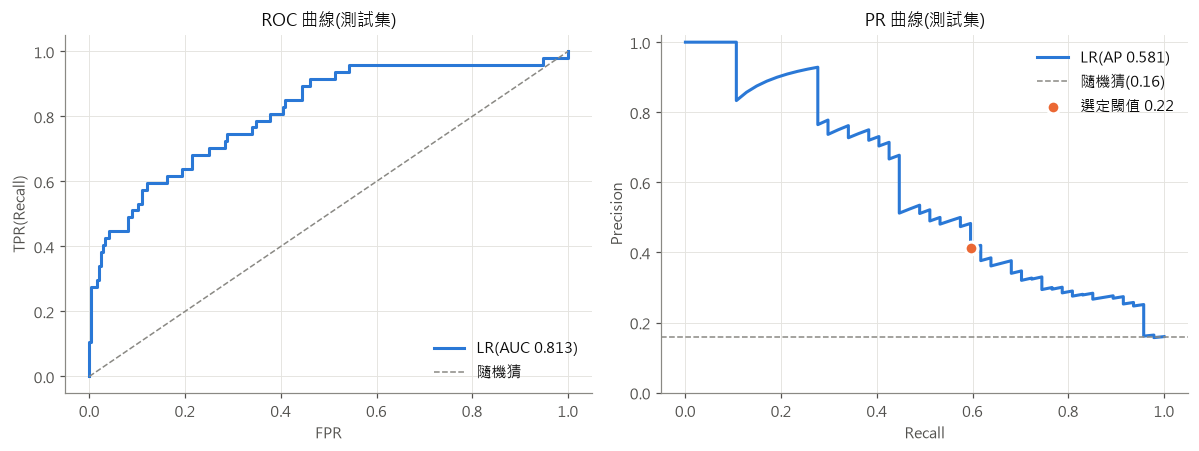

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[0].plot(fpr, tpr, color=C[0], lw=2, label=f"{FINAL_NAME}(AUC {roc_auc_score(y_test, p_test):.3f})")
axes[0].plot([0, 1], [0, 1], color="#8a8984", lw=1, ls="--", label="隨機猜")
axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR(Recall)"); axes[0].set_title("ROC 曲線(測試集)", fontsize=11)
axes[0].legend(frameon=False, loc="lower right")

prec, rec, _ = precision_recall_curve(y_test, p_test)
axes[1].plot(rec, prec, color=C[0], lw=2, label=f"{FINAL_NAME}(AP {average_precision_score(y_test, p_test):.3f})")
axes[1].axhline(y_test.mean(), color="#8a8984", lw=1, ls="--", label=f"隨機猜({y_test.mean():.2f})")
pt = (p_test >= THRESHOLD).astype(int)
axes[1].scatter([recall_score(y_test, pt)], [precision_score(y_test, pt)], s=70, color=C[1],
                edgecolor="white", linewidth=2, zorder=3, label=f"選定閾值 {THRESHOLD:.2f}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_ylim(0, 1.02)
axes[1].set_title("PR 曲線(測試集)", fontsize=11); axes[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "test_curves.png", bbox_inches="tight")
plt.show()

## 10. 補強分析

1. **公平性的不確定性**:各群組離職人數不多,用 bootstrap 估計 FPR / FNR 與群組差距的 95% 信賴區間。
2. **SMOTENC 對照**:SMOTE 會把 One-hot 欄位內插成小數;SMOTENC 專門處理類別欄位,檢查 3.3 對 SMOTE 的負面評價是否只是這個原因。
3. **40 歲以上漏判分析**:40+ 的 FNR 最高,比較「被抓到」與「沒被抓到」的離職者差在哪裡。

In [20]:
rng = np.random.default_rng(RANDOM_STATE)
grp = pd.DataFrame({"性別": X_train["Gender"].values,
                    "年齡層": age_group(X_train["Age"]).astype(str).values,
                    "y": y_train.values, "pred": pred})

def rates(d):
    pos, neg = d[d.y == 1], d[d.y == 0]
    return pos.pred.eq(0).mean(), neg.pred.eq(1).mean()      # FNR, FPR

def boot_ci(stat, B=2000):
    vals = []
    for _ in range(B):
        d = grp.iloc[rng.integers(0, len(grp), len(grp))]
        vals.append(stat(d))
    return np.percentile(np.array(vals), [2.5, 97.5], axis=0)

rows = []
for gname, levels in [("性別", ["Female", "Male"]), ("年齡層", ["<30", "30-39", "40+"])]:
    for lv in levels:
        f = lambda d, g=gname, l=lv: rates(d[d[g] == l])
        fnr, fpr = f(grp); ci = boot_ci(f)
        rows.append({"分組": gname, "群組": lv, "FNR": fnr, "FNR 95% CI": f"[{ci[0,0]:.2f}, {ci[1,0]:.2f}]",
                     "FPR": fpr, "FPR 95% CI": f"[{ci[0,1]:.2f}, {ci[1,1]:.2f}]"})
tab_fair_ci = pd.DataFrame(rows).round(3)

diffs = {
    "FNR:Male − Female": lambda d: rates(d[d["性別"] == "Male"])[0] - rates(d[d["性別"] == "Female"])[0],
    "FNR:40+ − <30": lambda d: rates(d[d["年齡層"] == "40+"])[0] - rates(d[d["年齡層"] == "<30"])[0],
    "FPR:<30 − 40+": lambda d: rates(d[d["年齡層"] == "<30"])[1] - rates(d[d["年齡層"] == "40+"])[1],
}
tab_diff = pd.DataFrame([{"差距": k, "估計": f(grp), "95% CI": "[{:.2f}, {:.2f}]".format(*boot_ci(f))}
                         for k, f in diffs.items()]).round(3)
tab_fair_ci.to_csv(REPORTS / "fairness_ci.csv", index=False)
tab_diff.to_csv(REPORTS / "fairness_gap_ci.csv", index=False)
display(tab_fair_ci); tab_diff

,分組,群組,FNR,FNR 95% CI,FPR,FPR 95% CI
0,性別,Female,0.239,"[0.14, 0.34]",0.162,"[0.13, 0.20]"
1,性別,Male,0.303,"[0.22, 0.39]",0.150,"[0.12, 0.18]"
2,年齡層,<30,0.149,"[0.07, 0.24]",0.255,"[0.19, 0.32]"
3,年齡層,30-39,0.307,"[0.21, 0.41]",0.145,"[0.11, 0.18]"
4,年齡層,40+,0.463,"[0.31, 0.62]",0.118,"[0.09, 0.15]"


,差距,估計,95% CI
0,FNR:Male − Female,0.063,"[-0.07, 0.19]"
1,FNR:40+ − <30,0.315,"[0.14, 0.50]"
2,FPR:<30 − 40+,0.137,"[0.07, 0.21]"


In [21]:
from imblearn.over_sampling import SMOTENC

def make_smotenc(name):
    """先做衍生特徵(類別欄位還是文字)→ SMOTENC → One-hot / 標準化 → 模型。"""
    base = make_model(name, "none")
    cats = [c for c in ["Department", "EducationField", "JobRole", "MaritalStatus", "Gender"] if c not in DROP]
    return Pipeline([base.steps[0],
                     ("resample", SMOTENC(categorical_features=cats, random_state=RANDOM_STATE)),
                     base.steps[1], base.steps[-1]])

res_nc = {}
for name in ["LR", "RF"]:
    res_nc[f"{name} | 不處理"] = res_ab[f"{name} | 不處理"]
    res_nc[f"{name} | SMOTE"] = res_ab[f"{name} | SMOTE"]
    res_nc[f"{name} | SMOTENC"] = run_cv(make_smotenc(name))
tab_nc = summarize(res_nc)
tab_nc.to_csv(REPORTS / "exp_smotenc.csv")
tab_nc

,ROC AUC,ROC sd,PR AUC,PR sd,Recall,Precision,F1
LR | 不處理,0.845,0.053,0.681,0.089,0.472,0.797,0.586
LR | SMOTE,0.834,0.054,0.642,0.093,0.744,0.408,0.525
LR | SMOTENC,0.825,0.060,0.627,0.099,0.516,0.618,0.558
RF | 不處理,0.803,0.051,0.558,0.096,0.212,0.807,0.328
RF | SMOTE,0.777,0.053,0.513,0.087,0.291,0.677,0.403
RF | SMOTENC,0.769,0.050,0.489,0.095,0.395,0.511,0.440


In [22]:
old = (age_group(X_train["Age"]).astype(str) == "40+").values & (y_train.values == 1)
d = X_train[old].copy()
d["被抓到"] = np.where(pred[old] == 1, "抓到", "漏掉")
d["預測機率"] = oof[old]
d["OverTime"] = (d["OverTime"] == "Yes").astype(int)
cols = ["預測機率", "OverTime", "MonthlyIncome", "JobLevel", "TotalWorkingYears", "YearsAtCompany",
        "NumCompaniesWorked", "JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance", "DistanceFromHome"]
tab_old = d.groupby("被抓到")[cols].median().T
tab_old["40+ 留任者"] = X_train[(age_group(X_train["Age"]).astype(str) == "40+").values & (y_train.values == 0)] \
    .assign(OverTime=lambda x: (x["OverTime"] == "Yes").astype(int), 預測機率=oof[(age_group(X_train["Age"]).astype(str) == "40+").values & (y_train.values == 0)])[cols].median()
tab_old.loc["人數"] = [int((d["被抓到"] == "抓到").sum()), int((d["被抓到"] == "漏掉").sum()),
                     int(((age_group(X_train["Age"]).astype(str) == "40+").values & (y_train.values == 0)).sum())]
print("中位數(OverTime 為比例)")
tab_old = tab_old.round(2)
tab_old.loc["OverTime"] = [d[d["被抓到"] == "抓到"]["OverTime"].mean().round(2),
                           d[d["被抓到"] == "漏掉"]["OverTime"].mean().round(2),
                           (X_train[(age_group(X_train["Age"]).astype(str) == "40+").values & (y_train.values == 0)]["OverTime"] == "Yes").mean().round(2)]
tab_old.to_csv(REPORTS / "error_analysis_40plus.csv")
tab_old

中位數(OverTime 為比例)


被抓到,抓到,漏掉,40+ 留任者
預測機率,0.59,0.03,0.03
OverTime,0.73,0.37,0.30
MonthlyIncome,6186.50,7978.00,7423.50
JobLevel,2.00,3.00,2.50
TotalWorkingYears,12.50,12.00,18.00
YearsAtCompany,4.00,9.00,6.00
NumCompaniesWorked,4.00,2.00,3.00
JobSatisfaction,3.00,3.00,3.00
EnvironmentSatisfaction,2.00,3.00,3.00
WorkLifeBalance,2.00,3.00,3.00
